This is a notebook to look into the data dicrepancies for MSP and International Falls.  

MSP had a location move 2000-2004 so we are going to inspect those records.  

International Falls is missing 2002 so we are going to inspect those records.  

The likely solution will be to splice the actual Chanhassen record into the MSP one,  
and splice in Littlefork data to the International Falls data

In [13]:
#dependencies and directory setup
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

data_dir= Path('../station_data/ghcnd/record_splices')
data_dir.mkdir(parents=True, exist_ok=True)

In [14]:
#pull the MSP and International Falls Records

#station ids
intl_falls='USW00014918'
msp='USW00014922'
chan= 'USC00211448'
lfork= 'USC00214809'

#noaa inventory of station data
url= ('https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/')

#lil func to stitch file paths and ,load data
def load_station(station_id):
    df=pd.read_csv(
        f'{url}/{station_id}.csv',
        parse_dates=['DATE'],
        low_memory=False,
    )
    return df.set_index('DATE').sort_index()

intl_falls_df=load_station(intl_falls)
msp_df=load_station(msp)
chan_df=load_station(chan)
lfork_df=load_station(lfork)



In [21]:
#slice em up and compare visually
msp_slice = msp_df.loc["1999":"2005"].copy()
chanhassen_slice = chan_df.loc["1999":"2005"].copy()

intl_falls_slice = intl_falls_df.loc["2001":"2003"].copy()
lfork_slice = lfork_df.loc["2001":"2003"].copy()


variables=['TMAX', 'TMIN','PRCP','SNOW','SNWD']
#clean first
def clean_for_comparison(df):
    #make missing vals nan
    values=df.reindex(columns=variables).apply(
        pd.to_numeric, errors='coerce'
    ).replace(-9999, float('nan'))

    for var in variables:
        attr_col=f'{var}_ATTRIBUTES'
        if attr_col in df.columns:
            flags=df[attr_col].fillna("").str.split(',')
            mflag=flags.str[0].fillna("").str.strip()
            qflag=flags.str[1].fillna("").str.strip()

            values.loc[mflag.eq('T'),var]=0
            values.loc[qflag.ne(""),var]=float("nan")

    values[['TMAX','TMIN','PRCP']]*=0.1
    return values


msp_compare=clean_for_comparison(msp_slice)
chanhassen_compare=clean_for_comparison(chanhassen_slice)
intl_falls_compare=clean_for_comparison(intl_falls_slice)
lfork_compare=clean_for_comparison(lfork_slice)

#compare the cleaned records to eachother
def monthly_coverage( left, right, left_name, right_name, start, end):
    dates=pd.date_range(start, end, freq='D')

    counts=pd.concat({
        left_name: left.reindex(dates).resample('MS').count(),
        right_name: right.reindex(dates).resample('MS').count(),
    }, axis=1)

    counts[('Expected', 'days_in_month')]=counts.index.days_in_month
    display(counts)

monthly_coverage(
    msp_compare, chanhassen_compare,
    'MSP', 'Chanhassen', '2000-01-01', '2004-12-31'
)

monthly_coverage(
    intl_falls_compare, lfork_compare,
    'Intenational Falls', 'Littlefork','2002-01-01', '2002-12-31'

)

MSP                     Chanhassen                      \
           TMAX TMIN PRCP SNOW SNWD       TMAX TMIN PRCP SNOW SNWD   
2000-01-01   31   31   31   31   31         31   31   31   31   30   
2000-02-01   29   29   29   29   29         28   29   29   29   29   
2000-03-01   31   31   31   31   31         31   30   31   31   31   
2000-04-01   30   30   30   30   30         30   28   30   30   30   
2000-05-01   31   31   31   31   31         31   31   31   31   31   
2000-06-01   30   30   30   30   30         30   29   30   30   30   
2000-07-01   31   31   31   31   31         31   31   31   31   31   
2000-08-01   31   31   31   31   31         31   31   31   31   31   
2000-09-01   30   30   30   30   30         30   29   30   30   30   
2000-10-01   31   31   31   31   31         31   31   31   31   31   
2000-11-01   30   30   30    0   12         30   30   30   30   30   
2000-12-01   31   31   31    0   24         30   29   31   31   30   
2001-01-01   31   31   31    0   31         30   31   31   31   31   
2001-02-01   28   28   28    0   26         28   26   28   28   28   
2001-03-01   31   31   31    0   29         31   31   31   31   31   
2001-04-01   30   30   30    0    0         30   29   30   30   30   
2001-05-01   31   31   31    0    0         31   31   31   31   31   
2001-06-01   30   30   30    0    0         30   29   30   30   30   
2001-07-01   31   31   31    0    0         31   31   31   31   31   
2001-08-01   31   31   31    0    0         31   31   31   31   31   
2001-09-01   30   30   30    0    0         30   30   30   30   30   
2001-10-01   31   31   31    0    0         31   31   31   31   31   
2001-11-01   30   30   30    0    3         30   29   30   30   30   
2001-12-01   31   31   31    0   11         31   31   31   31   31   
2002-01-01   31   31   31    0   19         31   31   31   31   31   
2002-02-01   28   28   28    0    9         28   28   28   28   28   
2002-03-01   31   31   31    0   15         31   30   31   31   31   
2002-04-01   30   30   30    0    4         30   30   30   30   30   
2002-05-01   31   31   31    0    0         31   30   31   31   31   
2002-06-01   30   30   30    0    0         30   30   30   30   30   
2002-07-01   31   31   31    0    0         31   31   31   31   31   
2002-08-01   31   31   31    0    0         31   31   31   31   31   
2002-09-01   30   30   30    0    0         30   30   30   30   30   
2002-10-01   31   31   31    0    0         30   31   31   31   31   
2002-11-01   30   30   30    0    0         30   30   30   30   30   
2002-12-01   31   31   31    0    5         31   30   31   31   31   
2003-01-01   31   31   31    0    5         31   31   31   31   31   
2003-02-01   28   28   28    0   24         27   28   28   28   28   
2003-03-01   31   31   31    0   12         31   30   31   31   31   
2003-04-01   30   30   30    0    0         30   30   30   30   30   
2003-05-01   31   31   31    0    0         31   31   31   31   31   
2003-06-01   30   30   30    0    0         30   30   30   30   30   
2003-07-01   31   31   31    0    0         30   30   31   31   31   
2003-08-01   31   31   31    0    0         31   31   31   31   31   
2003-09-01   30   30   30    0    0         30   30   30   30   30   
2003-10-01   31   31   31    0    0         31   31   31   31   31   
2003-11-01   30   30   30    0    7         30   30   30   30   30   
2003-12-01   31   31   31    0   20         31   31   31   31   31   
2004-01-01   31   31   31    0   31         31   31   31   31   31   
2004-02-01   29   29   29    0   29         29   29   29   29   29   
2004-03-01   31   31   31    0   31         31   31   31   31   31   
2004-04-01   30   30   30    0   30         30   30   30   30   30   
2004-05-01   31   31   31    0   31         31   31   31   31   31   
2004-06-01   30   30   30    0   30         30   30   30   30   30   
2004-07-01   31   31   31   31   31         31   31   31   31   31   
2004-08-01   31   31  

Intenational Falls                     Littlefork                 \
                         TMAX TMIN PRCP SNOW SNWD       TMAX TMIN PRCP SNOW   
2002-01-01                 31   31   31    0    0         31   31   31   31   
2002-02-01                 28   28   28    0    0         28   28   28   28   
2002-03-01                 31   31   31    0    0         31   31   31   31   
2002-04-01                 30   30   30    0    0         30   30   30   30   
2002-05-01                 31   31   31    0    0         31   31   31   31   
2002-06-01                 30   30   30    0    0         30   30   30   30   
2002-07-01                 31   31   31    0    0         31   31   31   31   
2002-08-01                 31   31   31    0    0         31   31   31   31   
2002-09-01                 30   30   30    0    0         30   30   30   30   
2002-10-01                 31   31   31    0    0         31   31   31   31   
2002-11-01                 30   30   30    0    0         30   30   30   30   
2002-12-01                 31   31   31   31   30         31   31   31   31   

                     Expected  
           SNWD days_in_month  
2002-01-01   31            31  
2002-02-01   28            28  
2002-03-01   31            31  
2002-04-01   30            30  
2002-05-01   31            31  
2002-06-01   30            30  
2002-07-01   31            31  
2002-08-01   31            31  
2002-09-01   30            30  
2002-10-01   31            31  
2002-11-01   30            30  
2002-12-01   31            31

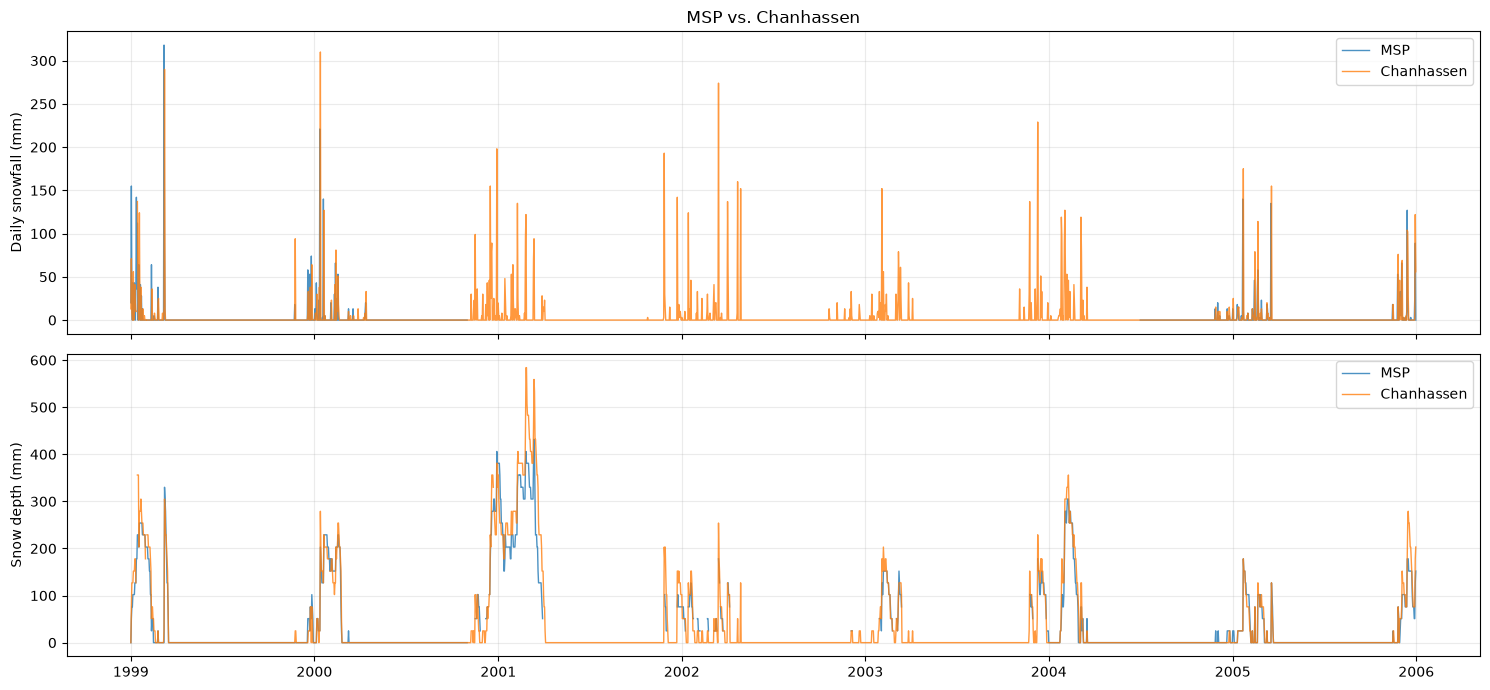

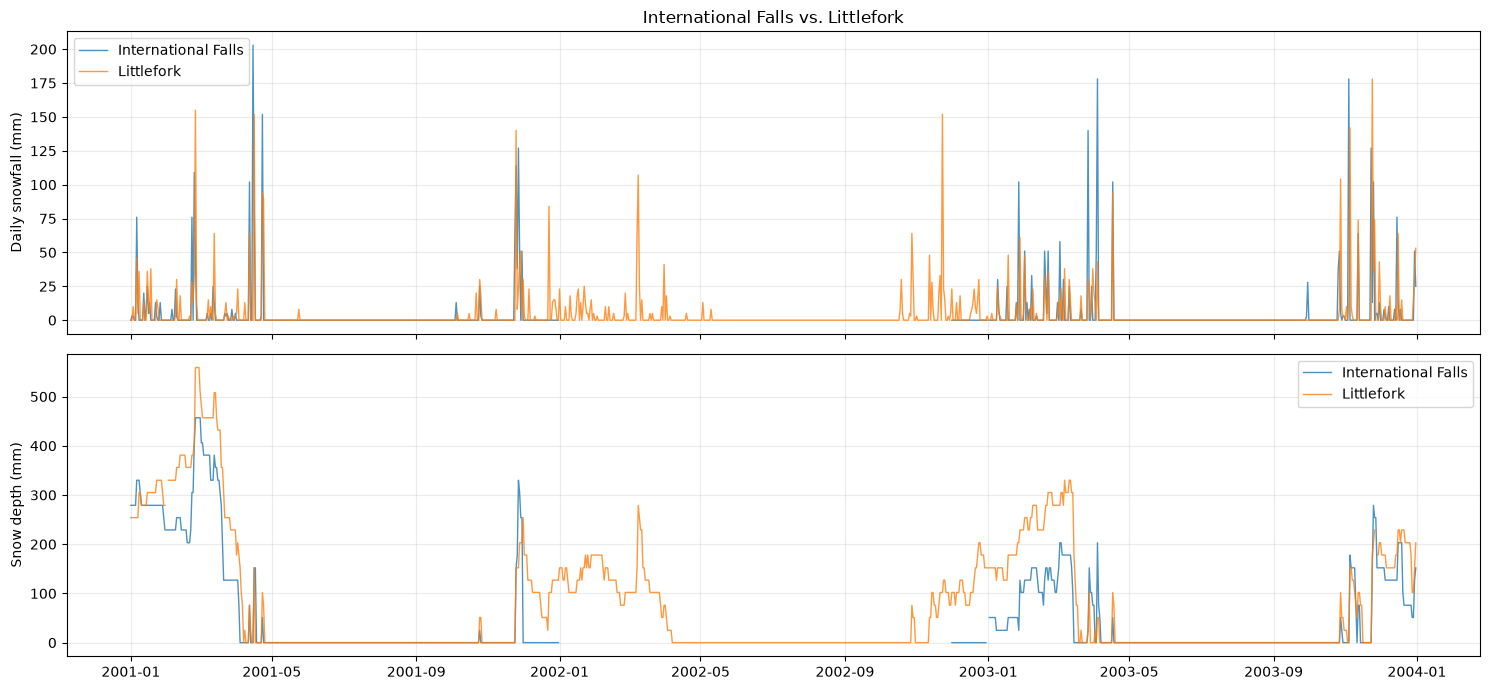

In [ ]:
def compare_snow(left, right, left_name, right_name, start, end):
    dates = pd.date_range(start, end, freq="D")
    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

    for ax, var, label in zip(
        axes, ["SNOW", "SNWD"], ["Daily snowfall (mm)", "Snow depth (mm)"]
    ):
        ax.plot(dates, left.reindex(dates)[var],
                label=left_name, linewidth=1, alpha=0.8)
        ax.plot(dates, right.reindex(dates)[var],
                label=right_name, linewidth=1, alpha=0.8)
        ax.set_ylabel(label)
        ax.legend()
        ax.grid(alpha=0.25)

    axes[0].set_title(f"{left_name} vs. {right_name}")
    plt.tight_layout()
    plt.show()

compare_snow(
    msp_compare, chanhassen_compare,
    "MSP", "Chanhassen", "1999-01-01", "2005-12-31",
)

compare_snow(
    intl_falls_compare, littlefork_compare,
    "International Falls", "Littlefork", "2001-01-01", "2003-12-31",
)

In [23]:
def snow_counts(df):
    tables = {}
    for var in ["SNOW", "SNWD"]:
        s = df[var]
        tables[var] = pd.DataFrame({
            "missing": s.isna(),
            "zero": s.eq(0),
            "positive": s.gt(0),
        }).groupby(s.index.year).sum()
    return pd.concat(tables, axis=1)

for name, df, start, end in [
    ("MSP", msp_compare, "1999", "2005"),
    ("Chanhassen", chanhassen_compare, "1999", "2005"),
    ("International Falls", intl_falls_compare, "2001", "2003"),
    ("Littlefork", littlefork_compare, "2001", "2003"),
]:
    print(name)
    dates = pd.date_range(f"{start}-01-01", f"{end}-12-31")
    display(snow_counts(df.reindex(dates)))

MSP


SNOW                  SNWD              
     missing zero positive missing zero positive
1999       0  340       25       0  301       64
2000      61  286       19      25  254       87
2001     365    0        0     265    0      100
2002     365    0        0     313    0       52
2003     365    0        0     297    0       68
2004     182  178        6       0  316       50
2005       0  327       38       0  281       84

Chanhassen


SNOW                  SNWD              
     missing zero positive missing zero positive
1999       2  332       31       4  297       64
2000       0  321       45       2  274       90
2001       0  326       39       0  254      111
2002       0  329       36       0  303       62
2003       0  326       39       0  286       79
2004       0  333       33       0  320       46
2005       0  322       43       0  281       84

International Falls


SNOW                  SNWD              
     missing zero positive missing zero positive
2001       0  324       41       0  261      104
2002     334   31        0     335   30        0
2003       1  316       48       1  234      130

Littlefork


SNOW                  SNWD              
     missing zero positive missing zero positive
2001       1  305       59       2  224      139
2002       0  299       66       0  216      149
2003       1  308       56       2  225      138

In [24]:
def missing_runs(df, var, start, end):
    dates = pd.date_range(start, end, freq="D")
    missing = df[var].reindex(dates).isna()
    groups = missing.ne(missing.shift()).cumsum()

    return (
        pd.DataFrame({"date": dates, "missing": missing, "group": groups})
        .loc[lambda x: x["missing"]]
        .groupby("group")
        .agg(start=("date", "min"), end=("date", "max"), days=("date", "size"))
        .reset_index(drop=True)
    )

for name, df, start, end in [
    ("MSP", msp_compare, "2000-01-01", "2004-12-31"),
    ("International Falls", intl_falls_compare, "2002-01-01", "2002-12-31"),
]:
    for var in ["SNOW", "SNWD"]:
        print(f"{name}: {var}")
        display(missing_runs(df, var, start, end))

MSP: SNOW


,start,end,days
0,2000-11-01,2004-06-30,1338


MSP: SNWD


,start,end,days
0,2000-11-01,2000-11-12,12
1,2000-11-14,2000-11-15,2
2,2000-11-27,2000-12-06,10
3,2000-12-13,2000-12-13,1
4,2001-02-12,2001-02-12,1
5,2001-02-16,2001-02-16,1
6,2001-03-17,2001-03-17,1
7,2001-03-31,2001-11-27,242
8,2001-12-03,2001-12-22,20
9,2002-01-09,2002-01-13,5


International Falls: SNOW


,start,end,days
0,2002-01-01,2002-11-30,334


International Falls: SNWD


,start,end,days
0,2002-01-01,2002-11-30,334
1,2002-12-31,2002-12-31,1
